In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/sarahhinkley/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

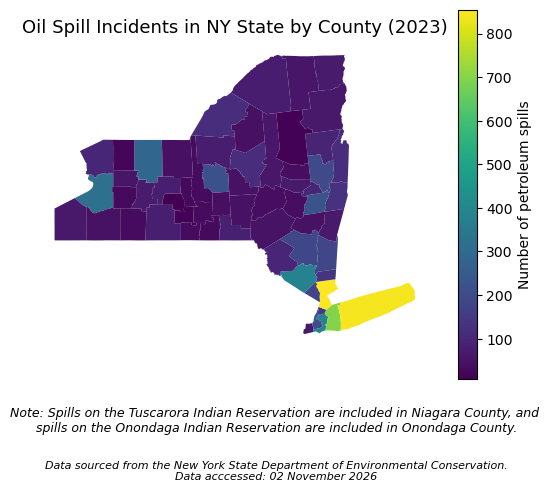

In [43]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Read in the NY spills data
fp = os.path.join('data', 'Spill_Incidents_20261103.csv')
spills = pd.read_csv(fp)

# Read in the spatial data of US counties
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)


# ----Clean the `spills` data----
# Update the column names in `spills` to lower case and replace spaces with _
spills.columns = spills.columns.str.lower().str.replace(" ", "_")

# Convert `spill_date` from object to datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date'])

# Store the petroleum spills from January 1, 2023 to December 31, 2023 as `petr_23`
petr_23 = spills[(spills['spill_date']>='2023-01-01') & (spills['spill_date']<='2023-12-31') & (spills['material_family']=='Petroleum')]

# Store the number of petroleum spills per NY county in 2023 as `spills_per_county`
spills_per_county = (petr_23.groupby('county').nunique()['spill_number'] # dataframe of unique values in every column for each county, keep the spill_number column
                            .reset_index() # set the index to integers instead of county
                            .rename(columns = {"spill_number":"n_spills"}))


# ----Clean the `counties` data----
# Update the columns in `counties` to be lowercase
counties.columns = counties.columns.str.lower()

# Using the metadata, find NY's FIPS to look at only the NY counties in the dataframe
ny_counties = counties[counties['statefp']== '36']


#----Prepare and merge dataframes----
# Update 'St Lawrence' to 'St. Lawrence' in `spills_per_county`
spills_per_county['county'] = spills_per_county['county'].replace({'St Lawrence':'St. Lawrence'}) 

# Change `name` column in `ny_counties` to `county` to match `spills_per_county`
ny_counties = ny_counties.rename(columns = {'name':'county'})

# Rename the reservations to their counties
spills_per_county['county'] = spills_per_county['county'].replace({ # `replace()` is for values inside of columns
    'Tuscarora Indian Reservation': 'Niagara',
    'Onondaga Indian Reservation': 'Onondaga'
})

# Niagara and Onondaga now appear twice in spills_per_county(their own spills plus the reservation spills),so group rows by `county` and add their spill counts into a single row per county
spills_per_county = spills_per_county.groupby('county').sum().reset_index()

# Merge `spills_per_county` and `ny_counties` by their common column: `county`
ny_spills = pd.merge(ny_counties, 
                      spills_per_county, 
                      how = 'inner',
                      on = 'county')


# ----Create a choropleth map of `ny_spills`----
fig, ax = plt.subplots()

ny_spills.plot(ax = ax, column = 'n_spills', # this parameter indicates which column to color by
                     legend = True,
                     legend_kwds = {'label': 'Number of petroleum spills'},
                     cmap = 'viridis'
              )

# Remove the axis for a cleaner map
ax.axis('off')

# Title for the plot
ax.set_title('Oil Spill Incidents in NY State by County (2023)',
              fontsize = 13)

# Add note about spills in reservations
plt.figtext(0.5, 0.0, 'Note: Spills on the Tuscarora Indian Reservation are included in Niagara County, and \n'
         'spills on the Onondaga Indian Reservation are included in Onondaga County.',
          ha = 'center', fontsize = 9, style = 'italic')

# Add caption with data source
plt.figtext(0.5, -0.10, 'Data sourced from the New York State Department of Environmental Conservation.\n'
            'Data acccessed: 02 November 2026',
             ha = 'center', fontsize = 8, style = 'italic')

plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

#### First dataset: oil spills data
The spill data come from the New York State Department of Environmental Conservation’s (DEC) Spill Incidents dataset, which records spills of petroleum and other hazardous materials reported to DEC. Under state law, spills that could pollute the land or waters of New York must be reported by the spiller. The DEC receives approximately 15,000 spill reports each year and about 90% of them involve petroleum products. Each record includes the spill number, date, location, contributing factor, source and cause, material spilled, quantities spilled and recovered, and any surface water affected. Spill locations were determined from mailing addresses, maps, or GPS. Because the data are self-reported and DEC cannot verify every report, some records may be incomplete or inaccurate, and many fields are blank.

New York State Department of Environmental Conservation. Spill Incidents. https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data. Accessed November 2, 2026. 

#### Second dataset: TIGER shapefile
The county boundaries come from the U.S. Census Bureau’s 2026 TIGER/Line Shapefiles, which contain the geographic boundaries of legal and statistical areas across the United States. The county shapefile includes every county in the country. This is a spatial (vector) dataset where each row represents one county and it is stored as a polygon of its boundary. The dataset also includes the county name and FIPS codes.

U.S. Census Bureau. (2026). 2026 TIGER/Line Shapefiles: Counties (and equivalent). https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html. Accessed November 2, 2026.

## 3. Import libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [3]:
# Read in the NY spills data
fp = os.path.join('data', 'Spill_Incidents_20261103.csv')
spills = pd.read_csv(fp)

# Read in the spatial data of US counties
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [4]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [5]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [6]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [7]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

In [8]:
# Number of rows and columns in dataframe
spills.shape

(574758, 20)

In [9]:
# Number of spills recorded in NY
spills['Spill Number'].nunique()

544687

_From this exploration of `spills`, I learned that there are more types of spills than just petroleum spills (although that is what our analysis is focused on). Also, there are 574,758 rows in `spills`, which you would think means one spill per row, however, in the metadata we learn that the same spill can take up multiple rows if the spill involved multiple materials. This is proven by looking at the amount of unique spill numbers (`spills['Spill Number'].nunique()`) in the data frame and seeing only 544,687 unique values. Also, by looking at the unique values in the `County` column of `spills` (`spills['County'].unique()`) I am seeing that there are some values (like `Vermont - Region 4` and `Canada - Region 9`) that do not seem to be a part of NY state and may have to later be manually removed or filtered out. Also, the column names have spaces between words and uppercase letters._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [10]:
# Update the column names in `spills` to lower case and replace spaces with _
spills.columns = spills.columns.str.lower().str.replace(" ", "_")

# Check the column names were updated
spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [11]:
# Convert `spill_date` from object to datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date'])

# Check the data types were updated
print(spills['spill_date'].dtype)

datetime64[ns]


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [12]:
# Create a variable to include only the dates of petroleum spills from January 1, 2023 to December 31, 2023
petr_23 = spills[(spills['spill_date']>='2023-01-01') & (spills['spill_date']<='2023-12-31') & (spills['material_family']=='Petroleum')]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [13]:
# Check only values from 2023 are in petr_23
print(f"petr_23 includes data from {petr_23['spill_date'].dt.year.unique()}.")
print(f"petr_23 includes data from {spills['spill_date'].dt.month.nunique()} months in 2023.")

petr_23 includes data from [2023].
petr_23 includes data from 12 months in 2023.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [14]:
# Checks that every row in the material_family is `Petroleum`
assert (petr_23['material_family'] == 'Petroleum').all()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [15]:
print(f"petr_23 has {len(petr_23)} rows.")
print(f"petr_23 includes {petr_23['spill_number'].nunique()} spills.")

petr_23 has 8468 rows.
petr_23 includes 8228 spills.


_There are 8,468 rows in `petr_23` and 8,228 unique `spill_number` values in `petr_23`. Clearly, these numbers are not the same, and in the metadata we learn that the same spill can take up multiple rows if the spill involved multiple materials. Therefore, I think that there being more rows in the data frame than spill number IDs means that there were a certain number of spills invloving multiple material types._

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [16]:
# Store the number of petroleum spills per NY county in 2023 as `spills_per_county`
spills_per_county = (petr_23.groupby('county').nunique()['spill_number'] # dataframe of unique values in every column for each county, keep the spill_number column
                            .reset_index() # set the index to integers instead of county
                            .rename(columns = {"spill_number":"n_spills"}))

In [17]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

In [18]:
# a Check the first five rows of `counties` geo-dataframe
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [19]:
# b Check the data types of the columns in `counties`
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [20]:
# c Check the CRS of `counties`
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

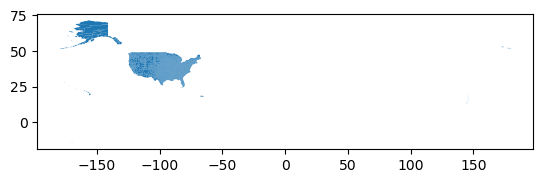

In [23]:
# d Plot the `counties` geo-dataframe
counties.plot()

e. Explain what you learn from the preliminary data exploration

_In `counties`, the names of the different NY counties are represented under a column called `name`, whereas in `spills` the different county names are represented under a column called `county`. Also, `counties` is spatial data (since it includes a `geometry` column and has a CRS). The column names are all uppercase. Another important thing to note is that `counties` includes all counties in all states across the U.S.A.. This is more data than we want to work with for this analysis focused on oil spills in NY state._



<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [24]:
# Update the columns in `counties` to be lowercase
counties.columns = counties.columns.str.lower()

# Check
counties.columns

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

<Axes: >

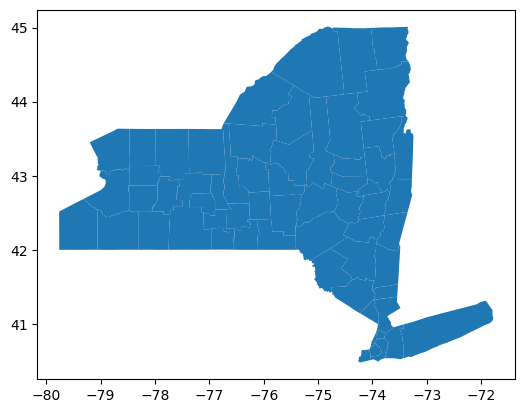

In [25]:
# Using the metadata, find NY's FIPS to look at only the NY counties in the dataframe
ny_counties = counties[counties['statefp']== '36']

ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [26]:
# Different counties in `ny_counties`
ny_diff_counties = ny_counties['name'].unique()

ny_diff_counties

array(['Erie', 'Niagara', 'Jefferson', 'Steuben', 'Seneca', 'Rensselaer',
       'Albany', 'Saratoga', 'Schoharie', 'Schenectady', 'Ulster',
       'Dutchess', 'Orange', 'Columbia', 'Tompkins', 'Tioga', 'Broome',
       'Cayuga', 'Genesee', 'Onondaga', 'Oswego', 'Madison', 'Livingston',
       'Monroe', 'Ontario', 'Orleans', 'Wayne', 'Chautauqua', 'Sullivan',
       'Chemung', 'Cattaraugus', 'Fulton', 'Montgomery', 'Cortland',
       'Warren', 'Washington', 'Otsego', 'Queens', 'Bronx', 'Nassau',
       'Westchester', 'Richmond', 'Kings', 'Suffolk', 'Rockland',
       'New York', 'Putnam', 'Clinton', 'St. Lawrence', 'Herkimer',
       'Oneida', 'Yates', 'Greene', 'Schuyler', 'Delaware', 'Hamilton',
       'Lewis', 'Allegany', 'Chenango', 'Wyoming', 'Franklin', 'Essex'],
      dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [27]:
# Different counties in `spills_per_county`
spills_counties = spills_per_county['county'].unique()

spills_counties

array(['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga',
       'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia',
       'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin',
       'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson',
       'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery',
       'Nassau', 'New Jersey - Region 2', 'New York', 'Niagara', 'Oneida',
       'Onondaga', 'Onondaga Indian Reservation', 'Ontario', 'Orange',
       'Orleans', 'Oswego', 'Otsego', 'Pennsylvania - Region 3', 'Putnam',
       'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga',
       'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St Lawrence',
       'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins',
       'Tuscarora Indian Reservation', 'Ulster', 'Warren', 'Washington',
       'Wayne', 'Westchester', 'Wyoming', 'Yates'], dtype=object)

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [28]:
# Check for the counties that are in `spills_per_county` but not in `ny_counties`
diff_names_spills = np.setdiff1d(spills_counties, ny_diff_counties)

diff_names_spills

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [29]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [30]:
# Check for the counties that are in `ny_counties` but not in `spills_per_county`
diff_names_ny = np.setdiff1d(ny_diff_counties, spills_counties)

diff_names_ny

array(['St. Lawrence'], dtype=object)

In [31]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [32]:
# e. Use a conditional statement with `spills_per_county` to see the number of spills in both reservations
spills_per_county[(spills_per_county['county']=='Tuscarora Indian Reservation') | (spills_per_county['county']=='Onondaga Indian Reservation')]

,county,n_spills
35,Onondaga Indian Reservation,1
58,Tuscarora Indian Reservation,2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [33]:
# Update 'St Lawrence' to 'St. Lawrence' in spills_per_county
spills_per_county['county'] = spills_per_county['county'].replace({'St Lawrence':'St. Lawrence'}) 

# Check the index value for 'St. Lawrence'
spills_per_county[spills_per_county['county'].str.contains("St. Lawrence")]

# Use the index location to create an assertion for checking if the name was updated
assert spills_per_county.loc[52, 'county'] == "St. Lawrence", f"The update was not successful, the county name is {spills_per_county.loc[52, 'county']}"

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [34]:
# a 
# Check if there are any common columns between `ny_countries` and `spills_per_county`
common_columns = set(ny_counties.columns).intersection(spills_per_county.columns)

if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else:
    print("No common columns")

No common columns


In [35]:
# Change `name` column in `ny_counties` to `county` to match `spills_per_county`
ny_counties = ny_counties.rename(columns = {'name':'county'})

# Now check if there is a column in common
common_columns = set(ny_counties.columns).intersection(spills_per_county.columns)

if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else:
    print("No common columns")

Common columns: {'county'}


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [36]:
# Now that there is a column in common, `spills_per_county` and `ny_counties` can be merged
ny_spills = pd.merge(ny_counties, 
                      spills_per_county, 
                      how = 'inner',
                      on = 'county')

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [37]:
# Counties in `spills_per_county` without a match in `ny_counties`
spills_per_county[~spills_per_county['county'].isin(ny_counties['county'])]

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

_Dropping `New Jersey - Region 2` and `Pennsylvania - Region 3` does NOT affect the map and information we are wanting to report because these regions are not located in NY state, therefore they should not be plotted on a map of the NY counties. However, dropping `Tuscaroroa Indian Reservation` and `Onondaga Indian Reservation` does affect the map and information we are wanting to report because, as we learned, Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. Therefore, the data from these reservations should be included in their respective counties._

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [38]:
# Save spill counts before the update for comparison:
counts_before = spills_per_county.set_index('county')['n_spills'] # `set_index('county')['n_spills']` lets us check the spills counts by calling the county name
print(f"Niagara County spills before update: {counts_before['Niagara']}")
print(f"Tuscarora Indian Reservation spills: {counts_before['Tuscarora Indian Reservation']}")
print(f"Onondaga County spills before update: {counts_before['Onondaga']}")
print(f"Onondaga Indian Reservation spills: {counts_before['Onondaga Indian Reservation']}")

Niagara County spills before update: 97
Tuscarora Indian Reservation spills: 2
Onondaga County spills before update: 214
Onondaga Indian Reservation spills: 1


In [39]:
# Rename the reservations to their counties
spills_per_county['county'] = spills_per_county['county'].replace({ # `replace()` is for values inside of columns
    'Tuscarora Indian Reservation': 'Niagara',
    'Onondaga Indian Reservation': 'Onondaga'
})

# Niagara and Onondaga now appear twice (their own spills plus the reservation spills),so group rows by `county` and add their spill counts into a single row per county
spills_per_county = spills_per_county.groupby('county').sum().reset_index()

# Save spills counts after the update for comparison: 
counts_after = spills_per_county.set_index('county')['n_spills']

print(f"After accounting for the number of spills in Tuscarora Indian Reservation, the value of Niagara County spills is now: {counts_after['Niagara']}")
print(f"After accounting for the number of spills in Onondaga Indian Reservation, the value of Onondaga County spills is now: {counts_after['Onondaga']}")

# Remerge `spills_per_county` and `ny_counties`
ny_spills = pd.merge(ny_counties, 
                      spills_per_county, 
                      how = 'inner',
                      on = 'county')

After accounting for the number of spills in Tuscarora Indian Reservation, the value of Niagara County spills is now: 99
After accounting for the number of spills in Onondaga Indian Reservation, the value of Onondaga County spills is now: 215


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



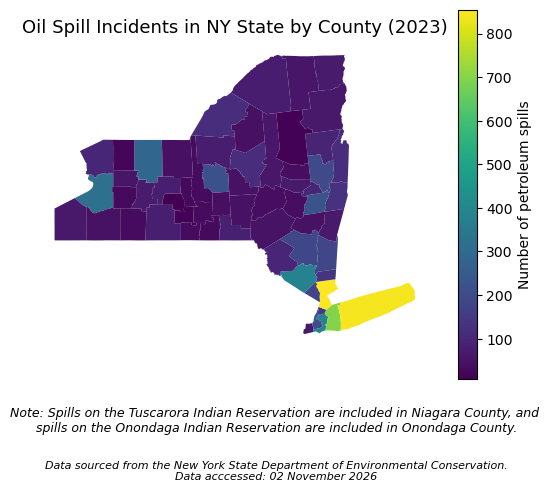

In [40]:
fig, ax = plt.subplots()

# Create a choropleth map of `ny_spills`
ny_spills.plot(ax = ax, column = 'n_spills', # this parameter indicates which column to color by
                     legend = True,
                     legend_kwds = {'label': 'Number of petroleum spills'},
                     cmap = 'viridis'
              )

# Remove the axis for a cleaner map
ax.axis('off')

# Title for the plot
ax.set_title('Oil Spill Incidents in NY State by County (2023)',
              fontsize = 13)

# Add note about spills in reservations
plt.figtext(0.5, 0.0, 'Note: Spills on the Tuscarora Indian Reservation are included in Niagara County, and \n'
         'spills on the Onondaga Indian Reservation are included in Onondaga County.',
          ha = 'center', fontsize = 9, style = 'italic')

# Add caption with data source
plt.figtext(0.5, -0.10, 'Data sourced from the New York State Department of Environmental Conservation.\n'
            'Data acccessed: 02 November 2026',
             ha = 'center', fontsize = 8, style = 'italic')

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

In [41]:
# Counties with highest number of petroleum spills in 2023
ny_spills.sort_values('n_spills', ascending=False).head(3)

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
40,36,119,00974157,36119,0500000US36119,Westchester,Westchester County,06,H1,G4020,408,35620,35614,A,1115811923,179391712,+41.1526862,-073.7457526,"POLYGON ((-73.65762 40.98550, -73.65739 40.985...",855
43,36,103,00974149,36103,0500000US36103,Suffolk,Suffolk County,06,H1,G4020,408,35620,35004,A,2359209021,3787486264,+40.9435540,-072.6922183,"POLYGON ((-71.80938 41.20323, -71.79115 41.184...",845
39,36,059,00974128,36059,0500000US36059,Nassau,Nassau County,06,H1,G4020,408,35620,35004,A,736965427,437285877,+40.7295039,-073.5894030,"POLYGON ((-73.78019 40.82640, -73.77498 40.830...",698


In [42]:
# Counties with lowest number of petroleum spills in 2023
ny_spills.sort_values('n_spills', ascending=False).tail(3)

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
53,36,097,00974146,36097,0500000US36097,Schuyler,Schuyler County,06,H1,G4020,None,None,None,A,850405401,36246372,+42.4197755,-076.9386030,"POLYGON ((-77.10711 42.48377, -77.10684 42.483...",13
55,36,041,00974119,36041,0500000US36041,Hamilton,Hamilton County,06,H1,G4020,None,None,None,A,4447989317,234204424,+43.6578786,-074.5024556,"POLYGON ((-74.20976 43.24926, -74.21149 43.249...",12
51,36,123,00974159,36123,0500000US36123,Yates,Yates County,06,H1,G4020,None,None,None,A,875850182,97496448,+42.6382370,-077.1043238,"POLYGON ((-77.35735 42.66919, -77.35734 42.669...",7


_This choropleth map shows the number of petroleum spills reported in each New York county in 2023. Spill records came from the New York State Department of Environmental Conservation’s Spill Incidents dataset and county boundaries came from the U.S. Census Bureau’s 2026 TIGER/Line Shapefiles. I filtered the spills data to incidents involving petroleum that occurred between January 1 and December 31, 2023, then counted the number of unique spill numbers in each county to avoid counting a single spill more than once when it involved multiple materials. I filtered the county boundaries to New York using its state FIPS code (36). Before merging the two datasets by county name, I changed the spelling of St. Lawrence County in one of the data frames to match the spelling in the other and assigned spills on the Tuscarora and Onondaga Indian Reservations to Niagara and Onondaga counties, since the reservations are not included as their own entities in the county data._

_The map shows that petroleum spills in 2023 were heavily concentrated in the New York City metropolitan area and Long Island. The counties with the highest recorded number of petroleum spills in 2023 are Westchester County (855 spills), Suffolk County (845 spills), and Nassau County (698 spills). The counties with the lowest recorded number of petroleum spills in 2023 are Yates County (7 spills), Hamilton County (12 spills), Schuyler County (13 spills). Also, since a few counties have far more spills than the rest, most of the state appears in similar dark colors, which makes it hard to better see the differences between the counties with less than 200 spills._

_Assigning the petroleum spills on the Tuscarora and Onondaga Indian Reservations to Niagara and Onondaga counties allowed every spill to appear on our county map, but it conflicts with the CARE Principles for Indigenous Data Governance. The Tuscarora and Onondaga Nations are sovereign nations and not parts of the surrounding counties, so merging their data into county totals disregards their authority to control data about their lands. It also limits the collective benefit of the data because this map basically makes their data invisible. The two reservations had only 3 spills combined, while Niagara and Onondaga counties had 97 and 214 spills. Merging them barely changed the map but made the reservations’ spills impossible to see. This makes it hard for the nations to use the map to understand or respond to environmental harms on their land. The map note makes this decision transpareny (which supports responsibility) but it would be better to report the reservations’ spills separately._

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.